In [1]:
import sys
sys.path.append("..")
 
import numpy as np
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from src.utils import get_distilbert_tokenizer, compress_random, compress_perplexity
from src.scorer import load_scorer, TokenScorer
 
scorer = load_scorer("../models/scorer.pt")
tok    = get_distilbert_tokenizer()
squad = load_dataset("rajpurkar/squad", split="validation")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [2]:
model = TokenScorer(freeze_encoder=True)
model.load_state_dict(torch.load("../models/scorer.pt", map_location="cpu"))
model.eval()

def compress_learned(text: str, ratio: float) -> dict:
    enc = tok(text, return_tensors="pt", truncation=True, max_length=512)
    with torch.no_grad():
        scores = model(enc.input_ids, enc.attention_mask).squeeze()
    tokens = tok.convert_ids_to_tokens(enc.input_ids.squeeze())
    k = max(1, int(len(tokens) * ratio))
    top_idx = sorted(torch.topk(scores, k).indices.tolist())
    kept_tokens = [tokens[i] for i in top_idx]
    compressed = tok.convert_tokens_to_string(kept_tokens)
    return {
        "compressed": compressed,
        "original_tokens": len(tokens),
        "kept_tokens": k,
        "ratio_actual": k / len(tokens),
        "scores": scores.tolist(),
        "tokens": tokens
    }

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [3]:
from evaluate import load
rouge = load("rouge")

results = []


In [4]:
for row in squad.select(range(100)):
    ctx = row["context"]
    for method, fn in [("random", compress_random),
                       ("perplexity", compress_perplexity),
                       ("learned", lambda t, r: compress_learned(t, r)["compressed"])]:
        for ratio in [0.3, 0.5, 0.7]:
            compressed = fn(ctx, ratio)
            score = rouge.compute(predictions=[compressed], references=[ctx])
            results.append({"method": method, "ratio": ratio,
                             "rouge1": score["rouge1"], "rouge2": score["rouge2"]})

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

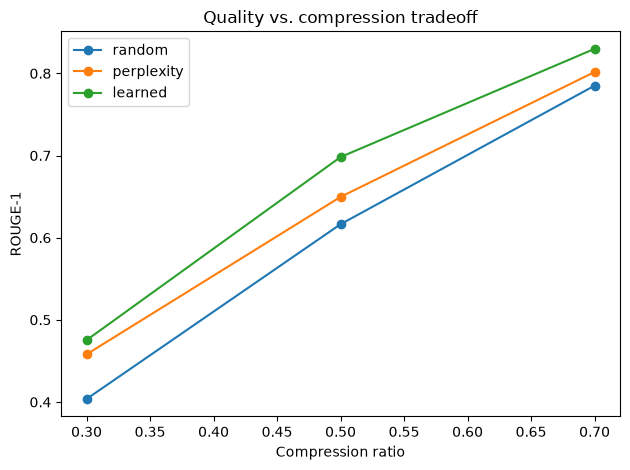

In [5]:
import pandas as pd
df = pd.DataFrame(results)
for method in ["random", "perplexity", "learned"]:
    sub = df[df.method == method].groupby("ratio")["rouge1"].mean()
    plt.plot(sub.index, sub.values, marker="o", label=method)
plt.xlabel("Compression ratio"); plt.ylabel("ROUGE-1")
plt.legend(); plt.title("Quality vs. compression tradeoff"); plt.tight_layout()
plt.savefig("../results/tradeoff_curve.png", dpi=150); plt.show()


In [6]:
summary = df.pivot_table(index="method", columns="ratio", values=["rouge1", "rouge2"]).round(3)
summary.to_csv("../results/rouge_summary.csv")
summary


rouge1               rouge2              
ratio         0.3    0.5    0.7    0.3    0.5    0.7
method                                              
learned     0.475  0.698  0.830  0.215  0.456  0.675
perplexity  0.458  0.650  0.802  0.125  0.352  0.563
random      0.404  0.616  0.785  0.114  0.295  0.539